In [19]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [20]:
# https://hbiostat.org/data/repo/titanic3.csv
df = pd.read_csv('data/titanic3.csv')
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


### ¿Cuánta gente sobrevivió (porcentualmente)?

In [21]:
df['survived'].value_counts(normalize=True)

survived
0    0.618029
1    0.381971
Name: proportion, dtype: float64

### ¿Y según el sexo?

In [22]:
df.groupby('sex')['survived'].mean()

sex
female    0.727468
male      0.190985
Name: survived, dtype: float64

### ¿Y según la clase?

In [23]:
df.groupby('pclass')['survived'].mean()

pclass
1    0.619195
2    0.429603
3    0.255289
Name: survived, dtype: float64

### Miramos la combinación de sexo y clase

In [24]:
df.groupby(['pclass', 'sex'])['survived'].mean()

pclass  sex   
1       female    0.965278
        male      0.340782
2       female    0.886792
        male      0.146199
3       female    0.490741
        male      0.152130
Name: survived, dtype: float64

### Ahora según el título nobiliario

In [25]:
# Parece que siempre sigue el mismo patrón: Apellido, Título. Nombre
df['title'] = df['name'].str.extract(r",\s*([A-Za-z]+)\.", expand=False)

title_mapping = {'Mlle': 'Miss',
                 'Ms': 'Miss',
                 'Mme': 'Mrs',
                 'Lady': 'Mrs',
                 'Sir': 'Mr'}

counts = df['title'].value_counts()
threshold = 5

title_mapping_other = {
    title: "Other" for title, count in counts.items() if count < threshold
}
title_mapping.update(title_mapping_other)

df['title'] = df['title'].replace(title_mapping)

df.groupby(df['title'])['survived'].mean().sort_values(ascending=False)

title
Mrs       0.786802
Miss      0.676923
Other     0.588235
Master    0.508197
Dr        0.500000
Mr        0.162483
Rev       0.000000
Name: survived, dtype: float64

### Finalmente según la cantidad de familiaries a bordo

In [26]:
df.groupby('sibsp')['survived'].mean()

sibsp
0    0.346801
1    0.510972
2    0.452381
3    0.300000
4    0.136364
5    0.000000
8    0.000000
Name: survived, dtype: float64

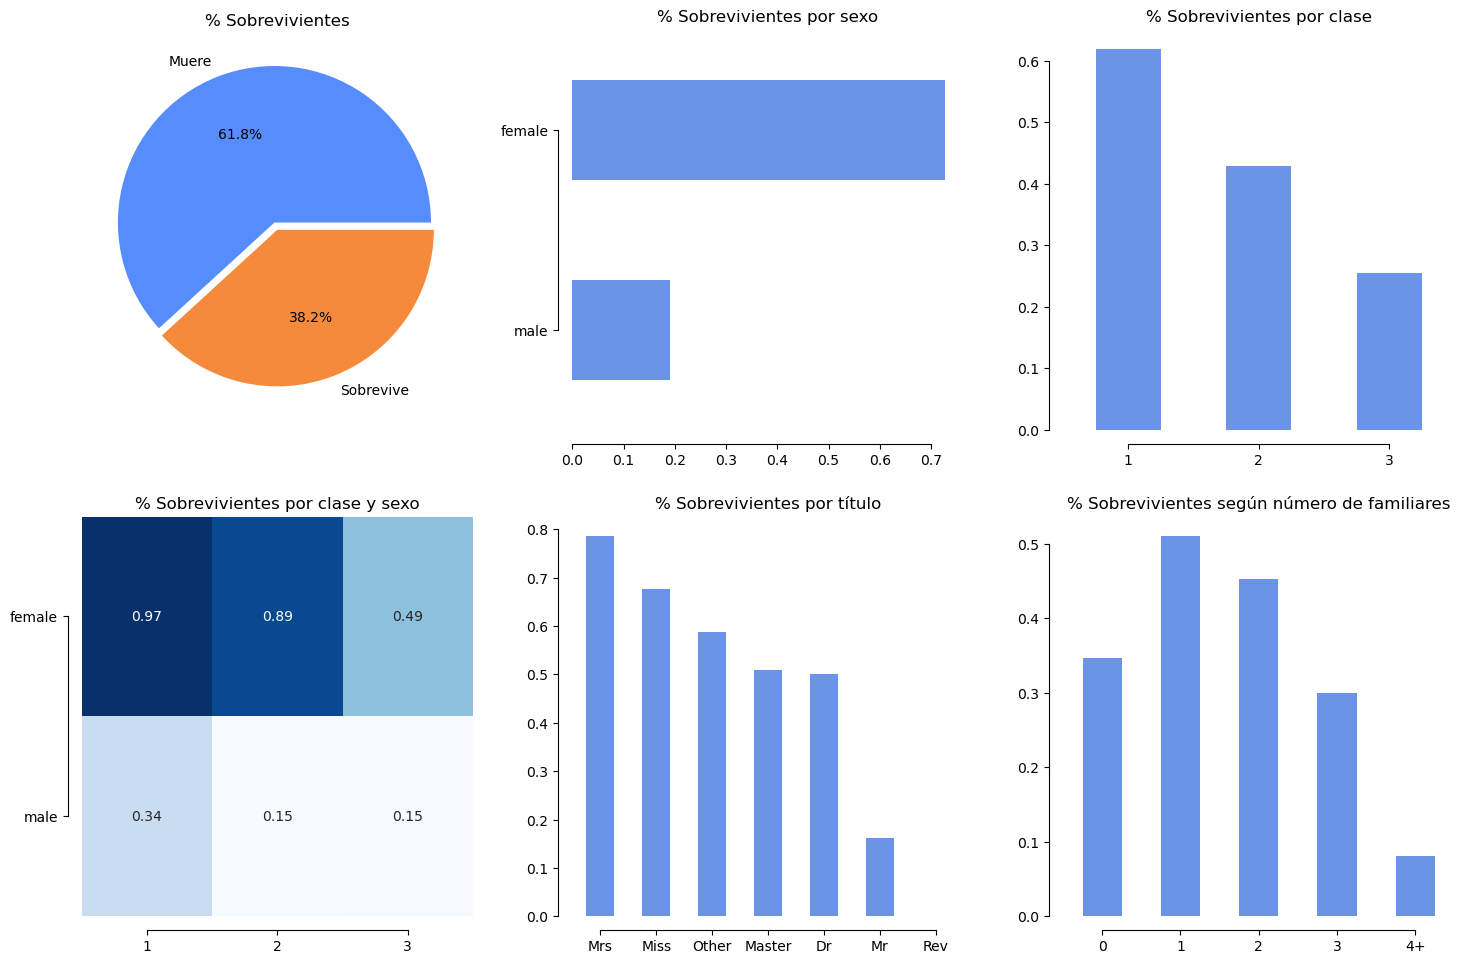

In [27]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axs = axs.flatten()

# 1 Pie chart
(df['survived']
.value_counts(normalize=True)
.rename(index={0: 'Muere', 1: 'Sobrevive'})
.plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axs[0],
    ylabel='',
    explode=[0.05, 0]
    ))
axs[0].set_title('% Sobrevivientes')

# 2 barras horizontales
data_graph_2 = df.groupby('sex')['survived'].mean()
sns.barplot( x=data_graph_2.values, y=data_graph_2.index, ax=axs[1], width=0.5)
axs[1].set_title('% Sobrevivientes por sexo')
axs[1].set_ylabel('')


# 3 barras verticales
data_graph_3 = df.groupby('pclass')['survived'].mean()
sns.barplot(x=data_graph_3.index, y=data_graph_3.values, ax=axs[2], width=0.5)
axs[2].set_title('% Sobrevivientes por clase')
axs[2].set_xlabel('')

# 4 heat map
data_graph_4 = df.groupby(['pclass', 'sex'])['survived'].mean()
sns.heatmap(data_graph_4.unstack().T, annot=True, cbar=False, cmap='Blues', ax=axs[3])
axs[3].set_title('% Sobrevivientes por clase y sexo')
axs[3].set_ylabel('')
axs[3].set_xlabel('')

# 5 barras verticales
data_graph_5 = df.groupby(df['title'])['survived'].mean().sort_values(ascending=False)
sns.barplot(x=data_graph_5.index, y=data_graph_5.values, ax=axs[4], width=0.5)
axs[4].set_title('% Sobrevivientes por título')
axs[4].set_xlabel('')

# 6 barras verticales
bins = [-1, 0, 1, 2, 3, np.inf]
labels = ["0", "1", "2", "3", "4+"]
data_graph_6 = df.groupby(
    pd.cut(df["sibsp"], bins=bins, labels=labels, right=True), observed=False
)["survived"].mean()
sns.barplot(x=data_graph_6.index, y=data_graph_6.values, ax=axs[5], width=0.5)
axs[5].set_title('% Sobrevivientes según número de familiares')
axs[5].set_xlabel('')

sns.despine(offset=10, trim=True)
plt.tight_layout(pad=2.0, w_pad=2.0, h_pad=2.0)
# plt.savefig('img/infografia.png')
plt.show()
